In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("weatherHistory.csv")

print("Dataset Shape:", df.shape)

df.head(10)

Dataset Shape: (96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
5,2006-04-01 05:00:00.000 +0200,Partly Cloudy,rain,9.222222,7.111111,0.85,13.9587,258.0,14.9569,0.0,1016.66,Partly cloudy throughout the day.
6,2006-04-01 06:00:00.000 +0200,Partly Cloudy,rain,7.733333,5.522222,0.95,12.3648,259.0,9.9820,0.0,1016.72,Partly cloudy throughout the day.
7,2006-04-01 07:00:00.000 +0200,Partly Cloudy,rain,8.772222,6.527778,0.89,14.1519,260.0,9.9820,0.0,1016.84,Partly cloudy throughout the day.
8,2006-04-01 08:00:00.000 +0200,Partly Cloudy,rain,10.822222,10.822222,0.82,11.3183,259.0,9.9820,0.0,1017.37,Partly cloudy throughout the day.
9,2006-04-01 09:00:00.000 +0200,Partly Cloudy,rain,13.772222,13.772222,0.72,12.5258,279.0,9.9820,0.0,1017.22,Partly cloudy throughout the day.


In [3]:
# Dataset information
df.info()

# Statistical summary
df.describe()

# Column names
print(df.columns)

# Check missing values
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 96453 entries, 0 to 96452
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Formatted Date            96453 non-null  str    
 1   Summary                   96453 non-null  str    
 2   Precip Type               95936 non-null  str    
 3   Temperature (C)           96453 non-null  float64
 4   Apparent Temperature (C)  96453 non-null  float64
 5   Humidity                  96453 non-null  float64
 6   Wind Speed (km/h)         96453 non-null  float64
 7   Wind Bearing (degrees)    96453 non-null  float64
 8   Visibility (km)           96453 non-null  float64
 9   Loud Cover                96453 non-null  float64
 10  Pressure (millibars)      96453 non-null  float64
 11  Daily Summary             96453 non-null  str    
dtypes: float64(8), str(4)
memory usage: 8.8 MB
Index(['Formatted Date', 'Summary', 'Precip Type', 'Temperature (C)',
       'Appare

In [4]:
data = df[
    [
        'Formatted Date',
        'Temperature (C)',
        'Humidity',
        'Wind Speed (km/h)'
    ]
].copy()

data.head()

,Formatted Date,Temperature (C),Humidity,Wind Speed (km/h)
0,2006-04-01 00:00:00.000 +0200,9.472222,0.89,14.1197
1,2006-04-01 01:00:00.000 +0200,9.355556,0.86,14.2646
2,2006-04-01 02:00:00.000 +0200,9.377778,0.89,3.9284
3,2006-04-01 03:00:00.000 +0200,8.288889,0.83,14.1036
4,2006-04-01 04:00:00.000 +0200,8.755556,0.83,11.0446


In [5]:
# Extract local calendar date from original timestamp
data['Date'] = pd.to_datetime(
    data['Formatted Date'].str[:10]
)

# Remove original date column
data.drop('Formatted Date', axis=1, inplace=True)

# Set date as index
data.set_index('Date', inplace=True)

# Convert hourly observations into daily averages
daily_data = data.resample('D').mean()

# Display results
daily_data.head(10)

,Temperature (C),Humidity,Wind Speed (km/h)
Date,,,
2006-01-01,3.873148,0.818333,21.372750
2006-01-02,5.418519,0.844583,17.551683
2006-01-03,2.319444,0.898333,8.417617
2006-01-04,2.274074,0.905417,11.579925
2006-01-05,2.698148,0.948333,9.515100
2006-01-06,2.511806,0.947083,5.665858
2006-01-07,0.992824,0.935833,6.699613
2006-01-08,-1.028009,0.868750,5.289521
2006-01-09,-1.848611,0.797083,5.247929


In [6]:
print("Missing values before handling:")
print(daily_data.isnull().sum())

# Handle missing values
daily_data = daily_data.interpolate(method='time')

daily_data = daily_data.ffill().bfill()

print("\nMissing values after handling:")
print(daily_data.isnull().sum())

Missing values before handling:
Temperature (C)      0
Humidity             0
Wind Speed (km/h)    0
dtype: int64

Missing values after handling:
Temperature (C)      0
Humidity             0
Wind Speed (km/h)    0
dtype: int64


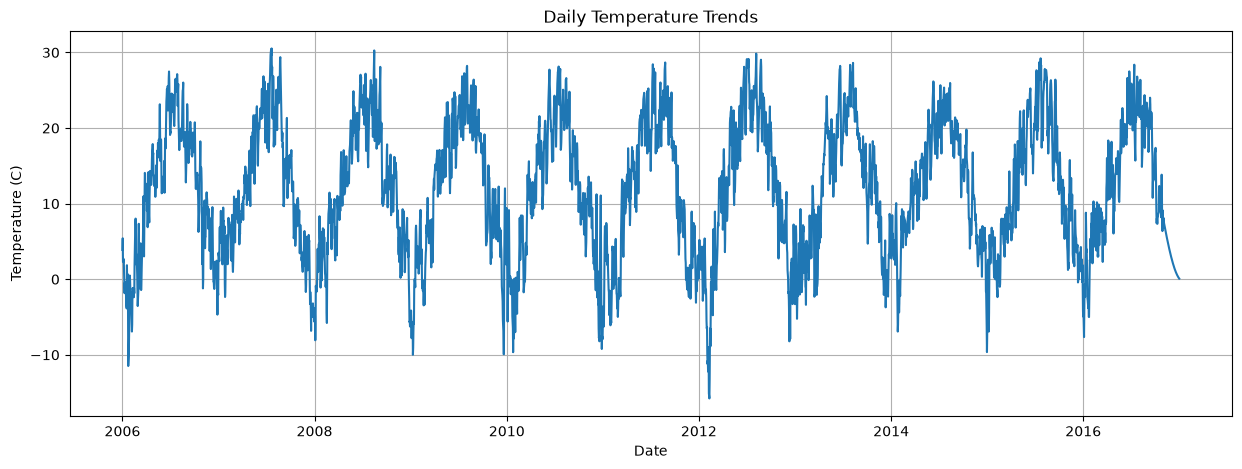

In [7]:
plt.figure(figsize=(15, 5))

plt.plot(
    daily_data.index,
    daily_data['Temperature (C)']
)

plt.title("Daily Temperature Trends")
plt.xlabel("Date")
plt.ylabel("Temperature (C)")

plt.grid(True)
plt.show()

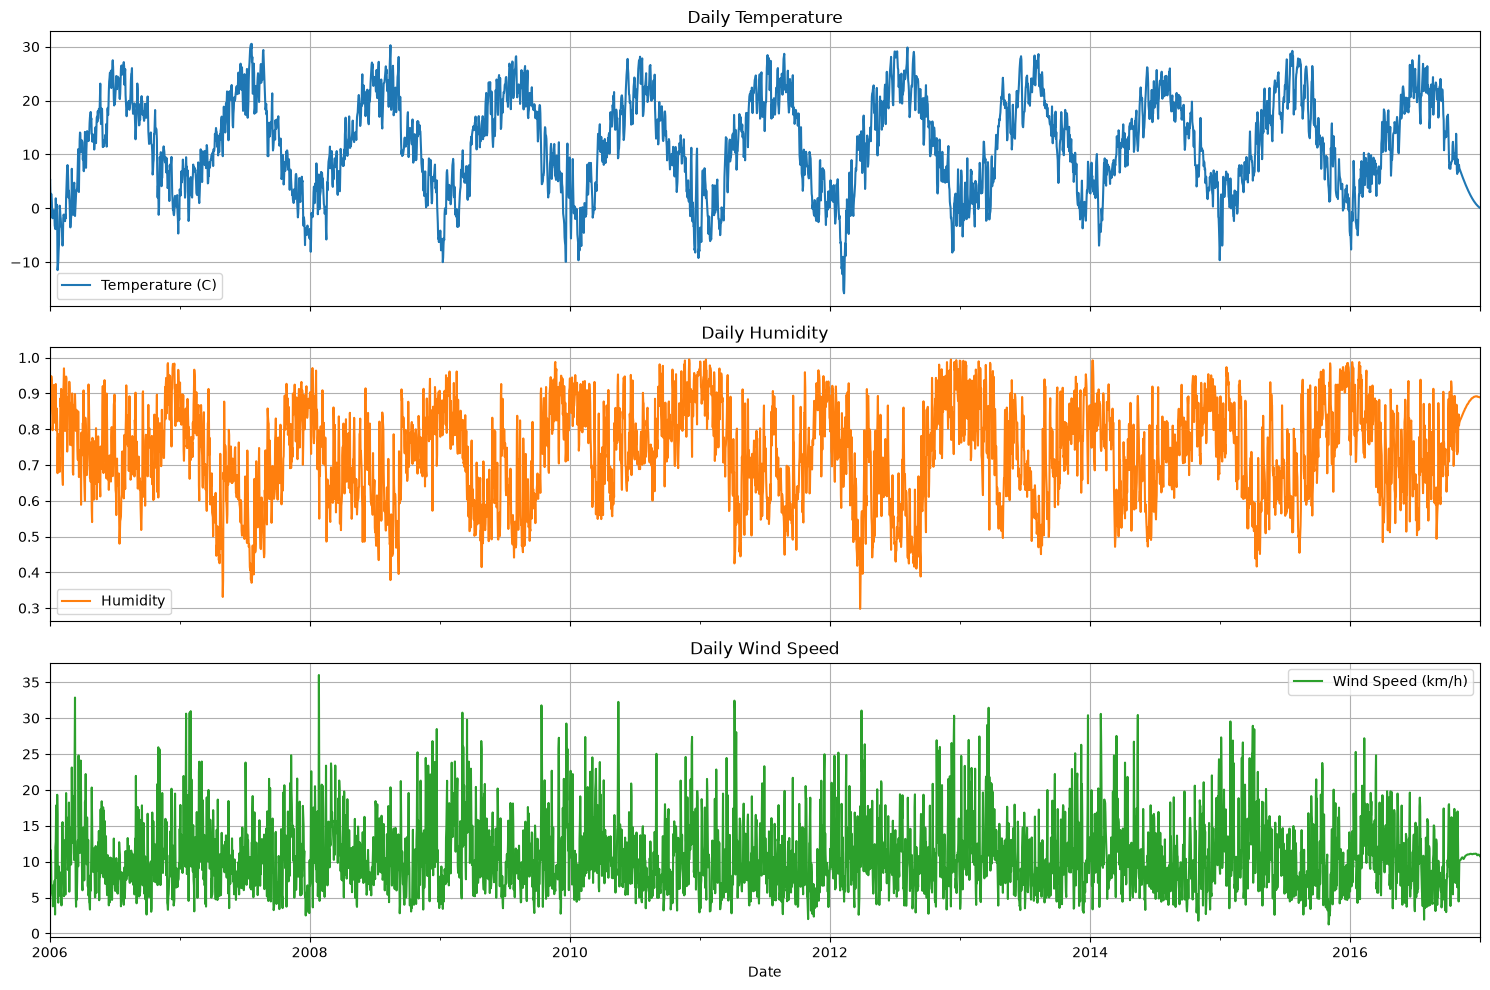

In [8]:
daily_data.plot(
    subplots=True,
    figsize=(15, 10),
    title=[
        'Daily Temperature',
        'Daily Humidity',
        'Daily Wind Speed'
    ],
    grid=True
)

plt.tight_layout()
plt.show()

In [11]:
from sklearn.preprocessing import MinMaxScaler

# Initialize scaler
scaler = MinMaxScaler(feature_range=(0, 1))

# Chronological split boundaries
n = len(daily_data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scaler ONLY on training data to prevent data leakage
scaler.fit(daily_data.iloc[:train_end])

# Transform the complete dataset
scaled_data = scaler.transform(daily_data)

# Convert back to DataFrame
scaled_df = pd.DataFrame(
    scaled_data,
    columns=daily_data.columns,
    index=daily_data.index
)

print(scaled_df.head())

            Temperature (C)  Humidity  Wind Speed (km/h)
Date                                                    
2006-01-01         0.424289  0.746563           0.569808
2006-01-02         0.457663  0.784220           0.457452
2006-01-03         0.390736  0.861327           0.188871
2006-01-04         0.389756  0.871488           0.281857
2006-01-05         0.398914  0.933054           0.221142


In [12]:
SEQ_LENGTH = 7

X = []
y = []
target_indices = []

values = scaled_df.values

for i in range(SEQ_LENGTH, len(values)):

    # Previous 7 days
    X.append(values[i-SEQ_LENGTH:i, :])

    # Next day's temperature (first column)
    y.append(values[i, 0])

    # Index of the target day
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4011, 7, 3)
y shape: (4011,)


In [13]:
# Split sequences based on the date of their target
train_mask = target_indices < train_end

val_mask = (
    (target_indices >= train_end) &
    (target_indices < val_end)
)

test_mask = target_indices >= val_end

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (2805, 7, 3) (2805,)
Validation: (603, 7, 3) (603,)
Testing: (603, 7, 3) (603,)


RNN Model Development

In [14]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [15]:
model = Sequential([

    SimpleRNN(
        units=64,
        activation='tanh',
        input_shape=(7, 3)
    ),

    Dropout(0.2),

    Dense(
        units=1,
        activation='linear'
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mean_absolute_error']
)

print("Model compiled successfully!")

Model compiled successfully!


In [17]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0535 - mean_absolute_error: 0.1709 - val_loss: 0.0053 - val_mean_absolute_error: 0.0579 - learning_rate: 0.0010
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0143 - mean_absolute_error: 0.0950 - val_loss: 0.0058 - val_mean_absolute_error: 0.0615 - learning_rate: 0.0010
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0095 - mean_absolute_error: 0.0777 - val_loss: 0.0034 - val_mean_absolute_error: 0.0461 - learning_rate: 0.0010
Epoch 4/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0086 - mean_absolute_error: 0.0736 - val_loss: 0.0032 - val_mean_absolute_error: 0.0450 - learning_rate: 0.0010
Epoch 5/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0074 - mean_absolute_error: 0.0682 - val_loss: 0.0030 - val_mean_absolute_error: 0.0432 - learning_rate: 0.0010
Epoch 6/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0068 - mean_absolute_error: 0.0654 - val_loss: 0.0028 - val_mean_absolute_

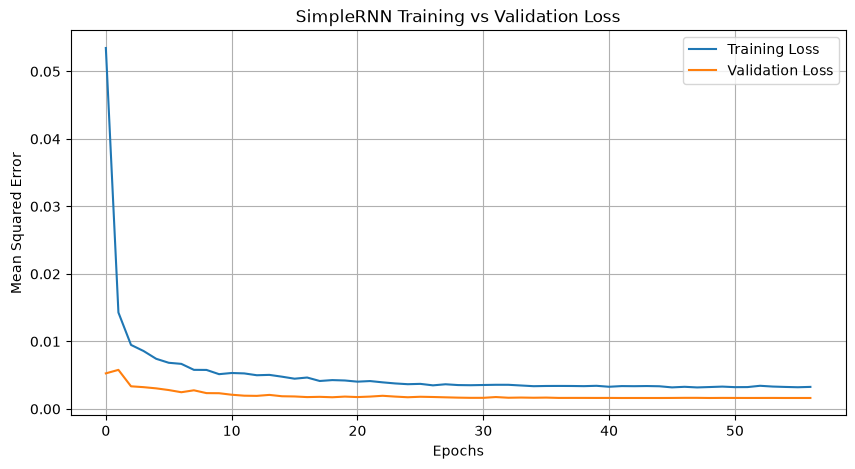

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('SimpleRNN Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')

plt.legend()
plt.grid(True)

plt.show()

Model Evaluation and Forecasting

In [19]:
y_pred = model.predict(X_test)

print("Prediction shape:", y_pred.shape)
print("Actual shape:", y_test.shape)

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
Prediction shape: (603, 1)
Actual shape: (603,)


In [20]:
temp_min = scaler.data_min_[0]
temp_range = scaler.data_range_[0]

# Inverse transformation
y_test_actual = y_test * temp_range + temp_min

y_pred_actual = y_pred.flatten() * temp_range + temp_min

print("Actual temperatures:")
print(y_test_actual[:10])

print("\nPredicted temperatures:")
print(y_pred_actual[:10])

Actual temperatures:
[18.2125     17.95416667 14.7650463  16.35185185 19.92731481 18.18796296
 13.81990741 15.10532407 17.62569444 17.6412037 ]

Predicted temperatures:
[17.43066791 18.68893195 16.96308275 14.65301636 17.88968604 20.42245947
 16.93722708 13.93267329 15.86094907 17.58773391]


In [26]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import numpy as np

# Calculate metrics
rmse = np.sqrt(
    mean_squared_error(y_test_actual, y_pred_actual)
)

mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

r2 = r2_score(
    y_test_actual,
    y_pred_actual
)

print("Model Evaluation Results")
print("------------------------")

print("RMSE:", round(rmse, 4), "°C")
print("MAE:", round(mae, 4), "°C")
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
RMSE: 1.9082 °C
MAE: 1.4406 °C
R2 Score: 0.949


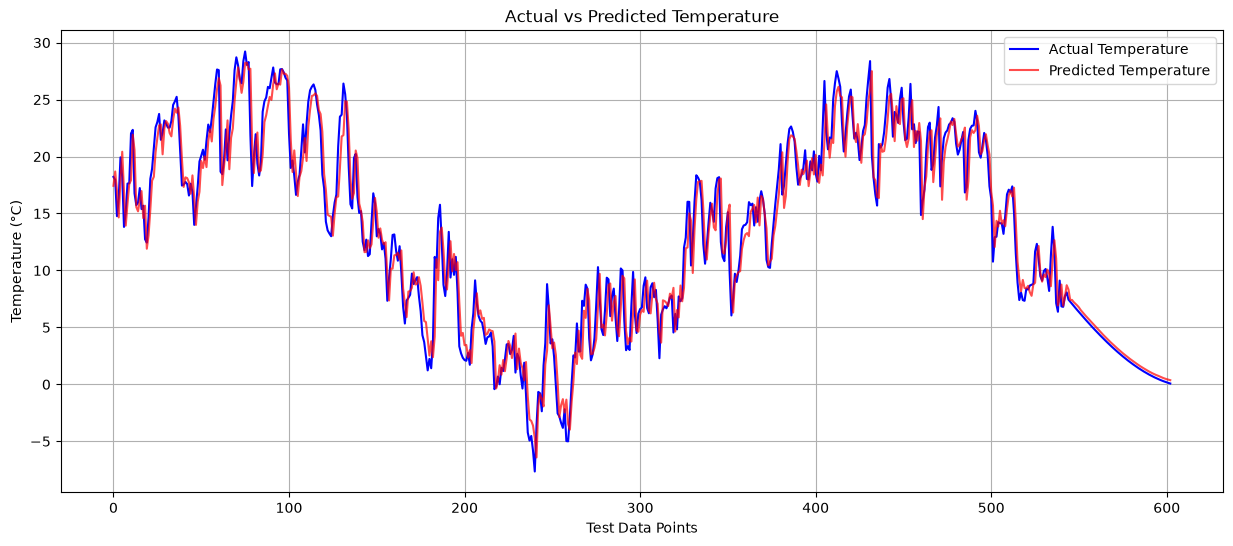

In [27]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test_actual,
    label='Actual Temperature',
    color='blue'
)

plt.plot(
    y_pred_actual,
    label='Predicted Temperature',
    color='red',
    alpha=0.7
)

plt.title('Actual vs Predicted Temperature')
plt.xlabel('Test Data Points')
plt.ylabel('Temperature (°C)')

plt.legend()
plt.grid(True)

plt.show()

In [28]:
# Get the last 7 days of historical data
last_sequence = scaled_df.values[-7:].copy()

future_predictions = []

for day in range(7):

    # Reshape input for RNN
    input_sequence = last_sequence.reshape(1, 7, 3)

    # Predict next day's normalized temperature
    next_temp = model.predict(
        input_sequence,
        verbose=0
    )[0, 0]

    # Store prediction
    future_predictions.append(next_temp)

    # Use latest known humidity and wind speed
    next_humidity = last_sequence[-1, 1]
    next_wind = last_sequence[-1, 2]

    # Create next day's feature row
    next_row = np.array([
        next_temp,
        next_humidity,
        next_wind
    ])

    # Update sequence
    last_sequence = np.vstack([
        last_sequence[1:],
        next_row
    ])

# Convert predictions to Celsius
future_predictions = (
    np.array(future_predictions) * temp_range + temp_min
)

print("Next 7 Days Temperature Forecast:")

for i, temp in enumerate(future_predictions, 1):
    print(f"Day {i}: {temp:.2f} °C")

Next 7 Days Temperature Forecast:
Day 1: 0.32 °C
Day 2: 0.56 °C
Day 3: 0.75 °C
Day 4: 0.90 °C
Day 5: 1.02 °C
Day 6: 1.13 °C
Day 7: 1.24 °C


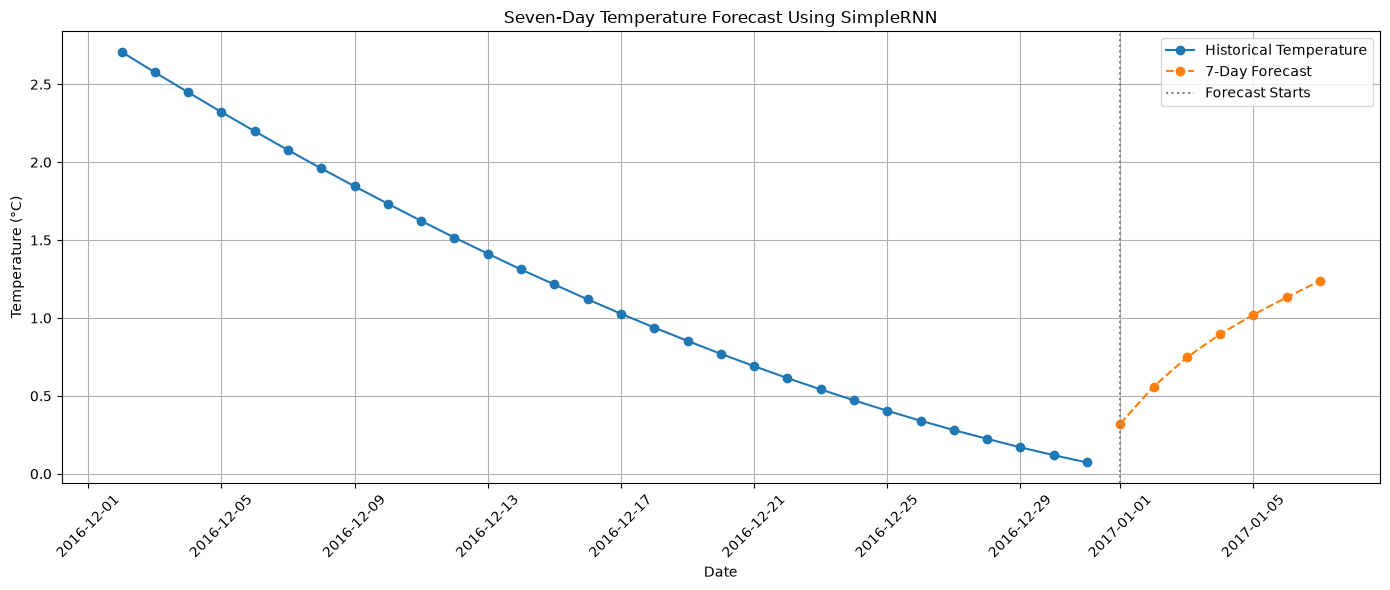

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_data.index[-30:],
    daily_data['Temperature (C)'].iloc[-30:],
    marker='o',
    label='Historical Temperature'
)

plt.plot(
    future_dates,
    future_predictions,
    marker='o',
    linestyle='--',
    label='7-Day Forecast'
)

plt.axvline(
    x=future_dates[0],
    color='gray',
    linestyle=':',
    label='Forecast Starts'
)

plt.title('Seven-Day Temperature Forecast Using SimpleRNN')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
print("FINAL MODEL PERFORMANCE")
print("=======================")

print(f"RMSE: {rmse:.4f} °C")
print(f"MAE:  {mae:.4f} °C")
print(f"R²:   {r2:.4f}")

FINAL MODEL PERFORMANCE
RMSE: 1.9082 °C
MAE:  1.4406 °C
R²:   0.9490


# Conclusion

In this assignment, a Simple Recurrent Neural Network (SimpleRNN) was developed using TensorFlow and Keras to predict daily temperatures based on historical weather observations.

The hourly weather dataset was converted into daily averages. Temperature, humidity, and wind speed were selected as input features. Missing values were handled, and MinMaxScaler was used for normalization.

A sequence length of seven days was selected to predict the temperature of the following day. The dataset was divided chronologically into training, validation, and testing sets to maintain the time-series order.

The SimpleRNN model consisted of 64 recurrent units, a Dropout layer with a rate of 0.2, and a Dense output layer with one neuron. The model was trained using the Adam optimizer and Mean Squared Error loss.

The final model achieved the following evaluation results:

- RMSE: 1.9082°C
- MAE: 1.4406°C
- R² Score: 0.9490

The actual versus predicted temperature visualization showed that the model successfully captured the general temperature patterns in the test dataset.

Finally, the trained model was used to generate a seven-day temperature forecast using recursive prediction.

Overall, the results demonstrate that SimpleRNN can learn useful temporal patterns from historical weather data and perform next-day temperature prediction. However, the seven-day forecast has limitations because future humidity and wind speed values were assumed to remain constant.